# Importing

In [280]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
from matplotlib.font_manager import FontProperties
rcParams.update({
    'figure.autolayout': False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"],
    })
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42


RESULTS_DIR = 'results'
pt1_df = pd.read_csv(f'{RESULTS_DIR}/ccn_pt1.csv')

# Fig 1

## v0

lffa p-values - All r: 6.892098554810175e-102, Preferred r: 6.470591376765016e-07, Non-preferred r: 2.064639818027182e-59
lffa p-values - All r: 2.3708849645581086e-50, Preferred r: 0.3404814418316912, Non-preferred r: 3.2603510971904867e-25
rffa p-values - All r: 1.5459153787648917e-89, Preferred r: 3.5480525085847394e-05, Non-preferred r: 8.624256082593896e-39
rffa p-values - All r: 1.9822717819963864e-63, Preferred r: 0.002002610245131533, Non-preferred r: 1.086434667069583e-34
leba p-values - All r: 4.96453054583281e-65, Preferred r: 3.829763275307167e-06, Non-preferred r: 2.4201637693127297e-27
leba p-values - All r: 7.384670745686688e-55, Preferred r: 3.908994921414518e-05, Non-preferred r: 7.291430258234464e-26
reba p-values - All r: 1.894038490423808e-75, Preferred r: 3.2090111516225815e-07, Non-preferred r: 7.96846920583235e-34
reba p-values - All r: 2.1699093608187405e-62, Preferred r: 1.0381519181469658e-07, Non-preferred r: 2.481197788282481e-32


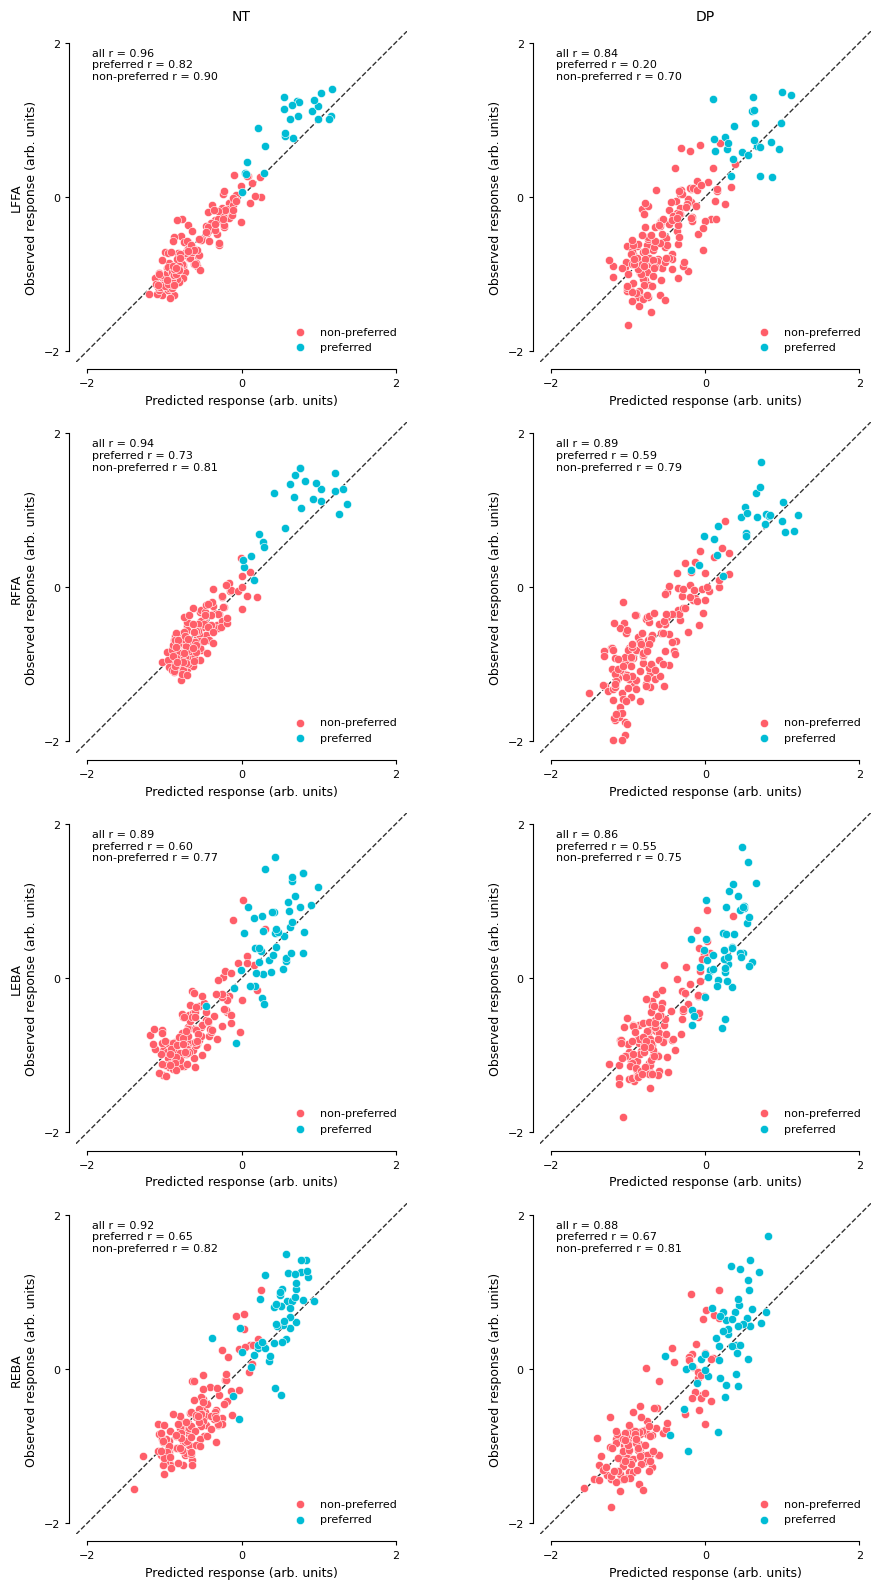

In [166]:
savefig = False
plot_dir = f'{RESULTS_DIR}/plots'

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')
# subtypes = results_csv['subject_type'].unique()
subtypes = ['nt', 'dp']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']

fig, axs = plt.subplots(len(frois_considered), len(subtypes), figsize=(10, 16), sharex=False, sharey=False)

# First pass: collect all data and calculate global limits for each FROI
# froi_limits = {}
# for i, froi in enumerate(frois_considered):
#     all_predictions = []
#     all_observations = []
    
#     for j, subtype in enumerate(subtypes):
#         df_sub = results_csv[
#             (results_csv['froi'] == froi) &
#             (results_csv['subject_type'] == subtype)
#         ].copy()

#         df_stage1 = (
#             df_sub
#             .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
#             .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
#         )

#         df_final = (
#             df_stage1
#             .groupby(['overall_img_idx', 'img_cat'], as_index=False)
#             .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
#         )
        
#         all_predictions.extend(df_final['y_prediction'].values)
#         all_observations.extend(df_final['y_observed'].values)
    
#     # Calculate limits for this FROI
#     min_val = min(min(all_predictions), min(all_observations))
#     max_val = max(max(all_predictions), max(all_observations))
#     pad = 0.05 * (max_val - min_val)
#     froi_limits[froi] = [min_val - pad, max_val + pad]

froi_limits = {
    'lffa': [-2.15, 2.15],
    'rffa': [-2.15, 2.15],
    'leba': [-2.15, 2.15],
    'reba': [-2.15, 2.15]
}
froi_ticks = {
    'lffa': [-2, 0, 2],
    'rffa': [-2, 0, 2],
    'leba': [-2, 0, 2],
    'reba': [-2, 0, 2]
}

# Second pass: plot with consistent limits per FROI
for i, froi in enumerate(frois_considered):
    for j, subtype in enumerate(subtypes):
        ax = axs[i, j]

        preferred_stim = None
        if 'ffa' in froi:
            preferred_stim = 'faces'
        elif 'eba' in froi:
            preferred_stim = 'bodies'

        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        df_final = (
            df_stage1
            .groupby(['overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        mask_preferred = df_final['img_cat'] == preferred_stim
        mask_nonpreferred = ~mask_preferred

        r_preferred, pval_preferred = pearsonr(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed']
        )
        r_nonpreferred, pval_nonpreferred = pearsonr(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed']
        )
        r_all, pval_all = pearsonr(df_final['y_prediction'], df_final['y_observed'])
        print(f'{froi} p-values - All r: {pval_all}, Preferred r: {pval_preferred}, Non-preferred r: {pval_nonpreferred}')

        # scatter points
        ax.scatter(
            df_final.loc[mask_nonpreferred, 'y_prediction'],
            df_final.loc[mask_nonpreferred, 'y_observed'],
            color='#ff5e69',
            alpha=1,
            s=35,
            edgecolor='white',
            linewidth=0.4,
            label='non-preferred',
            zorder=3
        )
        ax.scatter(
            df_final.loc[mask_preferred, 'y_prediction'],
            df_final.loc[mask_preferred, 'y_observed'],
            color='#00bcd5',
            alpha=1,
            s=35,
            edgecolor='white',
            linewidth=0.4,
            label='preferred',
            zorder=3
        )

        lims = froi_limits[froi]

        ax.plot(lims, lims, 'k--', linewidth=1, alpha=0.8, zorder=2)
        ax.set_xlim(lims)
        ax.set_ylim(lims)

        if i==0:
            ax.set_title(subtype.upper(), fontsize=10, pad=8)
        ax.set_xlabel('Predicted response (arb. units)', fontsize=9)
        if j==0:
            ax.set_ylabel(f'{froi.upper()}\nObserved response (arb. units)', fontsize=9)
        else:
            ax.set_ylabel('Observed response (arb. units)', fontsize=9)

        ax.text(
            0.05, 0.95,
            f'all r = {r_all:.2f}\npreferred r = {r_preferred:.2f}\nnon-preferred r = {r_nonpreferred:.2f}',
            transform=ax.transAxes,
            va='top',
            fontsize=8,
            bbox=dict(facecolor='white', alpha=0.85, edgecolor='none', pad=2)
        )

        ax.legend(fontsize=8, frameon=False, loc='lower right')
        ax.set_aspect('equal', adjustable='box')

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_position(('outward', 5))
        ticks = np.array(froi_ticks.get(froi, []))
        ax.spines['bottom'].set_bounds(ticks.min(), ticks.max())
        ax.spines['left'].set_bounds(ticks.min(), ticks.max())

        ax.tick_params(axis='both', labelsize=8, length=3, width=0.8)
        ax.set_xticks(froi_ticks.get(froi, []))
        ax.set_yticks(froi_ticks.get(froi, []))

plt.tight_layout()
for ax in axs.flat:
    ax.set_box_aspect(1)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## v1

### x-axis = NT/DP

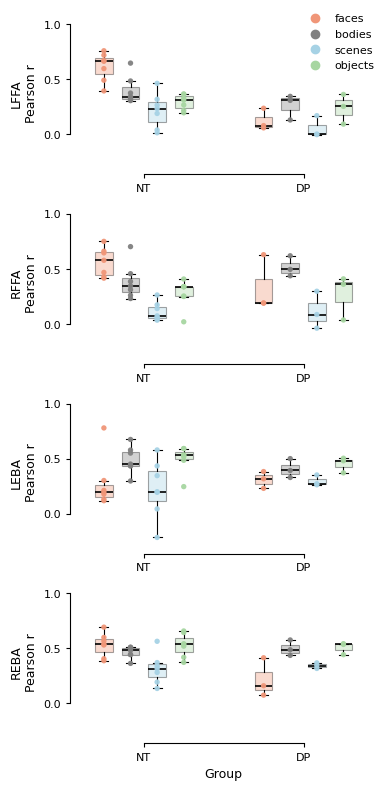

In [233]:
savefig = False
plot_dir = f'{RESULTS_DIR}/plots'

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')
# subtypes = results_csv['subject_type'].unique()
subtypes = ['nt', 'dp']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']
categories = ['faces', 'bodies', 'scenes', 'objects']

fig, axs = plt.subplots(len(frois_considered), 1, figsize=(4, 8), sharex=False, sharey=False)

froi_limits = {
    'lffa': [-2.15, 2.15],
    'rffa': [-2.15, 2.15],
    'leba': [-2.15, 2.15],
    'reba': [-2.15, 2.15]
}
froi_ticks = {
    'lffa': [-2, 0, 2],
    'rffa': [-2, 0, 2],
    'leba': [-2, 0, 2],
    'reba': [-2, 0, 2]
}

# Boxplots of subject-level category correlations (Predicted vs Observed), grouped by subtype
# category_colors = {
#     'faces': '#00bcd5',
#     'bodies': '#4caf50',
#     'scenes': '#9c27b0',
#     'objects': '#ff5e69'
# }

category_colors = {
    'faces': '#f09678',
    'scenes': '#a6d2e5',
    'objects': '#a7d6a1',
    'bodies': '#808080',
}

for i, froi in enumerate(frois_considered):
    ax = axs[i]

    corr_rows = []
    for subtype in subtypes:
        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        # average across repeated entries first
        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        for subject in sorted(df_stage1['test_subject'].unique()):
            for cat in categories:
                dcat = df_stage1[
                    (df_stage1['test_subject'] == subject) &
                    (df_stage1['img_cat'] == cat)
                ]

                if len(dcat) < 2:
                    r = np.nan
                elif dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                    r = np.nan
                else:
                    r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                corr_rows.append({
                    'froi': froi,
                    'subject_type': subtype,
                    'test_subject': subject,
                    'img_cat': cat,
                    'r': r
                })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    # positions: 4 NT + gap + 4 DP
    step = 0.3
    group_gap = 0.6

    nt_pos = np.arange(4) * step
    dp_pos = nt_pos + nt_pos[-1] + group_gap + step
    subtype_to_pos = {'nt': nt_pos, 'dp': dp_pos}

    nt_center = nt_pos.mean()
    dp_center = dp_pos.mean()

    for subtype in subtypes:
        for cidx, cat in enumerate(categories):
            pos = subtype_to_pos[subtype][cidx]
            vals = corr_df.loc[
                (corr_df['subject_type'] == subtype) &
                (corr_df['img_cat'] == cat), 'r'
            ].values

            if len(vals) == 0:
                continue

            ax.boxplot(
                [vals],
                positions=[pos],
                widths=0.2,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor=category_colors[cat], alpha=0.35, edgecolor='black', linewidth=0.8), # 
                medianprops=dict(color='black', linewidth=1.2),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8)
            )

            x_jitter = rng.normal(loc=pos, scale=0, size=len(vals))
            ax.scatter(
                x_jitter, vals,
                s=15, alpha=0.95, color=category_colors[cat],
                edgecolor='none', linewidth=0.4, zorder=3
            )
    
    if i==0:
        # Add a custom legend for category colors
        legend_elements = [plt.Line2D([0], [0], color=category_colors[cat], marker='o', lw=0, label=cat) for cat in categories]
        ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.05, 1.1), fontsize=8, frameon=False)

    # axis labels/ticks
    ax.set_xlim(-0.3, 3)
    ax.set_ylim(-0.3, 1.05)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_xticks([np.mean(nt_pos), np.mean(dp_pos)])
    ax.set_xticklabels(['NT', 'DP'], fontsize=8)

    # if i == 0:
    #     ax.text(1.5, 1.02, 'NT', transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=10)
    #     ax.text(6.5, 1.02, 'DP', transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=10)

    # ax.axvline(4.0, color='k', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.set_ylabel(f'{froi.upper()}\nPearson r', fontsize=9)
    if i==3:
        ax.set_xlabel('Group', fontsize=9)

    # preserve axis style
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(0, 1)
    ax.spines['bottom'].set_bounds(np.mean(nt_pos), np.mean(dp_pos))
    ax.tick_params(axis='both', labelsize=8, length=3, width=0.8)

plt.tight_layout()
# for ax in axs.flat:
#     ax.set_box_aspect(1)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### x-axis = Category

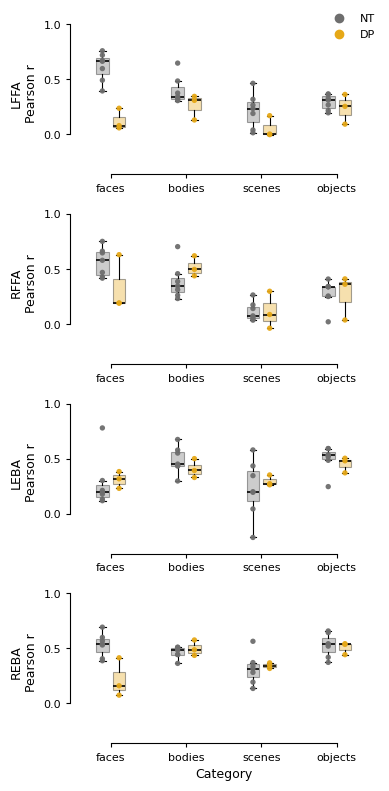

In [249]:
savefig = False
plot_dir = f'{RESULTS_DIR}/plots'

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')
# subtypes = results_csv['subject_type'].unique()
subtypes = ['nt', 'dp']
frois_considered = ['lffa', 'rffa', 'leba', 'reba']
categories = ['faces', 'bodies', 'scenes', 'objects']

fig, axs = plt.subplots(len(frois_considered), 1, figsize=(4, 8), sharex=False, sharey=False)

froi_limits = {
    'lffa': [-2.15, 2.15],
    'rffa': [-2.15, 2.15],
    'leba': [-2.15, 2.15],
    'reba': [-2.15, 2.15]
}
froi_ticks = {
    'lffa': [-2, 0, 2],
    'rffa': [-2, 0, 2],
    'leba': [-2, 0, 2],
    'reba': [-2, 0, 2]
}

# Boxplots of subject-level category correlations (Predicted vs Observed), grouped by subtype
# category_colors = {
#     'faces': '#00bcd5',
#     'bodies': '#4caf50',
#     'scenes': '#9c27b0',
#     'objects': '#ff5e69'
# }

category_colors = {
    'faces': '#f09678',
    'scenes': '#a6d2e5',
    'objects': '#a7d6a1',
    'bodies': '#808080',
}
subtype_colors = {
    'nt': '#6e6e6e',  # Blue 
    'dp': '#E6A817'   # Orange
}

for i, froi in enumerate(frois_considered):
    ax = axs[i]

    corr_rows = []
    for subtype in subtypes:
        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        # average across repeated entries first
        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        for subject in sorted(df_stage1['test_subject'].unique()):
            for cat in categories:
                dcat = df_stage1[
                    (df_stage1['test_subject'] == subject) &
                    (df_stage1['img_cat'] == cat)
                ]

                if len(dcat) < 2:
                    r = np.nan
                elif dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                    r = np.nan
                else:
                    r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                corr_rows.append({
                    'froi': froi,
                    'subject_type': subtype,
                    'test_subject': subject,
                    'img_cat': cat,
                    'r': r
                })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    # positions: 4 categories, each with NT and DP side-by-side
    step = 0.2
    group_gap = 0.5

    # For each category, create NT and DP positions
    cat_positions = {}
    for cidx, cat in enumerate(categories):
        cat_center = cidx * (step * 2 + group_gap)
        cat_positions[cat] = {
            'nt': cat_center,
            'dp': cat_center + step
        }

    nt_centers = [cat_positions[cat]['nt'] for cat in categories]
    dp_centers = [cat_positions[cat]['dp'] for cat in categories]

    for subtype in subtypes:
        for cidx, cat in enumerate(categories):
            pos = cat_positions[cat][subtype]
            vals = corr_df.loc[
                (corr_df['subject_type'] == subtype) &
                (corr_df['img_cat'] == cat), 'r'
            ].values

            if len(vals) == 0:
                continue

            ax.boxplot(
                [vals],
                positions=[pos],
                widths=0.15,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor=subtype_colors[subtype], alpha=0.35, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1.2),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8)
            )

            x_jitter = rng.normal(loc=pos, scale=0, size=len(vals))
            ax.scatter(x_jitter, vals, s=15, alpha=0.95, color=subtype_colors[subtype],
                    edgecolor='none', linewidth=0.4, zorder=3)
    
    if i == 0:
        # Category legend
        # category_legend = [
        #     plt.Line2D([0], [0], color=category_colors[cat], marker='o', lw=0, label=cat)
        #     for cat in categories
        # ]
        # leg1 = ax.legend(
        #     handles=category_legend,
        #     loc='upper right',
        #     bbox_to_anchor=(1.05, 1.1),
        #     fontsize=8,
        #     frameon=False,
        #     title='Category',
        #     title_fontsize=8
        # )
        # ax.add_artist(leg1)

        # Subtype legend
        subtype_legend = [
            plt.Line2D([0], [0], color=subtype_colors[st], marker='o', lw=0, label=st.upper())
            for st in subtypes
        ]
        ax.legend(
            handles=subtype_legend,
            loc='upper right',
            bbox_to_anchor=(1.05, 1.1),
            fontsize=8,
            frameon=False,
            # title='Subtype',
            title_fontsize=8
        )

    # Update x-axis ticks
    xticks = [np.mean([cat_positions[cat]['nt'], cat_positions[cat]['dp']]) for cat in categories]
    ax.set_xticks(xticks)
    ax.set_xticklabels(categories, fontsize=8)
    ax.set_xlim(-0.3, cat_positions[categories[-1]]['dp'] + 0.3)

    # axis labels/ticks
    # ax.set_xlim(-0.3, 3)
    ax.set_ylim(-0.3, 1.05)
    ax.set_yticks([0.0, 0.5, 1.0])

    # if i == 0:
    #     ax.text(1.5, 1.02, 'NT', transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=10)
    #     ax.text(6.5, 1.02, 'DP', transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=10)

    # ax.axvline(4.0, color='k', linestyle='--', linewidth=0.8, alpha=0.7)
    ax.set_ylabel(f'{froi.upper()}\nPearson r', fontsize=9)
    if i==3:
        ax.set_xlabel('Category', fontsize=9)

    # preserve axis style
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(0, 1)
    ax.spines['bottom'].set_bounds(np.min(xticks), np.max(xticks))
    ax.tick_params(axis='both', labelsize=8, length=3, width=0.8)

plt.tight_layout()
# for ax in axs.flat:
#     ax.set_box_aspect(1)

if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### Hemispheres combined

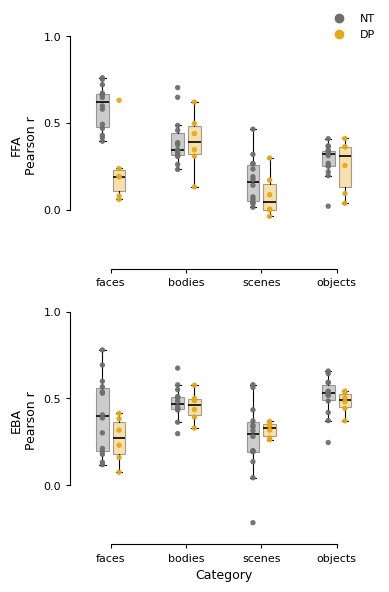

In [250]:
# Group FROIs by hemisphere
froi_groups = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba']
}

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')

fig, axs = plt.subplots(2, 1, figsize=(4, 6), sharex=False, sharey=False)

for row_idx, (froi_group_name, froi_list) in enumerate(froi_groups.items()):
    ax = axs[row_idx]
    
    corr_rows = []
    for froi in froi_list:
        for subtype in subtypes:
            df_sub = results_csv[
                (results_csv['froi'] == froi) &
                (results_csv['subject_type'] == subtype)
            ].copy()

            df_stage1 = (
                df_sub
                .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
                .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
            )

            for subject in sorted(df_stage1['test_subject'].unique()):
                for cat in categories:
                    dcat = df_stage1[
                        (df_stage1['test_subject'] == subject) &
                        (df_stage1['img_cat'] == cat)
                    ]

                    if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                        r = np.nan
                    else:
                        r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                    corr_rows.append({
                        'froi': froi,
                        'subject_type': subtype,
                        'test_subject': subject,
                        'img_cat': cat,
                        'r': r
                    })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    # Position setup for 2 groups of FROIs
    step = 0.2
    group_gap = 0.5
    cat_positions = {}
    for cidx, cat in enumerate(categories):
        cat_center = cidx * (step * 2 + group_gap)
        cat_positions[cat] = {
            'nt': cat_center,
            'dp': cat_center + step
        }

    # Plot boxplots and scatter
    for subtype in subtypes:
        for cidx, cat in enumerate(categories):
            pos = cat_positions[cat][subtype]
            vals = corr_df.loc[
                (corr_df['subject_type'] == subtype) &
                (corr_df['img_cat'] == cat), 'r'
            ].values

            if len(vals) == 0:
                continue

            ax.boxplot([vals], positions=[pos], widths=0.15, patch_artist=True,
                      showfliers=False,
                      boxprops=dict(facecolor=subtype_colors[subtype], alpha=0.35, edgecolor='black', linewidth=0.8),
                      medianprops=dict(color='black', linewidth=1.2),
                      whiskerprops=dict(color='black', linewidth=0.8),
                      capprops=dict(color='black', linewidth=0.8))

            x_jitter = rng.normal(loc=pos, scale=0, size=len(vals))
            ax.scatter(x_jitter, vals, s=15, alpha=0.95, color=subtype_colors[subtype],
                      edgecolor='none', linewidth=0.4, zorder=3)

    xticks = [np.mean([cat_positions[cat]['nt'], cat_positions[cat]['dp']]) for cat in categories]
    ax.set_xticks(xticks)
    ax.set_xticklabels(categories, fontsize=8)
    ax.set_xlim(-0.3, cat_positions[categories[-1]]['dp'] + 0.3)
    ax.set_ylim(-0.3, 1.05)
    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_ylabel(f'{froi_group_name.upper()}\nPearson r', fontsize=9)
    
    if row_idx == 1:
        ax.set_xlabel('Category', fontsize=9)
    
    if row_idx == 0:
        subtype_legend = [
            plt.Line2D([0], [0], color=subtype_colors[st], marker='o', lw=0, label=st.upper())
            for st in subtypes
        ]
        ax.legend(handles=subtype_legend, loc='upper right', bbox_to_anchor=(1.05, 1.1),
                 fontsize=8, frameon=False)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_position(('outward', 5))
    ax.spines['left'].set_position(('outward', 5))
    ax.spines['left'].set_bounds(0, 1)
    ax.spines['bottom'].set_bounds(np.min(xticks), np.max(xticks))
    ax.tick_params(axis='both', labelsize=8, length=3, width=0.8)

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig2.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


### Stats

In [251]:
from scipy.stats import mannwhitneyu

# Mann-Whitney U: NT vs DP within each fROI/category
# Compute subject-level category correlations first
mw_rows = []

for froi in frois_considered:
    corr_rows = []
    for subtype in subtypes:
        df_sub = results_csv[
            (results_csv['froi'] == froi) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        for subject in sorted(df_stage1['test_subject'].unique()):
            for cat in categories:
                dcat = df_stage1[
                    (df_stage1['test_subject'] == subject) &
                    (df_stage1['img_cat'] == cat)
                ]

                if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                    r = np.nan
                else:
                    r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                corr_rows.append({
                    'froi': froi,
                    'subject_type': subtype,
                    'test_subject': subject,
                    'img_cat': cat,
                    'r': r
                })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    for cat in categories:
        nt_vals = corr_df.loc[
            (corr_df['subject_type'] == 'nt') & (corr_df['img_cat'] == cat), 'r'
        ].values
        dp_vals = corr_df.loc[
            (corr_df['subject_type'] == 'dp') & (corr_df['img_cat'] == cat), 'r'
        ].values

        if len(nt_vals) > 0 and len(dp_vals) > 0:
            u_stat, p_value = mannwhitneyu(nt_vals, dp_vals, alternative='two-sided')
        else:
            u_stat, p_value = np.nan, np.nan

        mw_rows.append({
            'froi': froi,
            'category': cat,
            'n_nt': len(nt_vals),
            'n_dp': len(dp_vals),
            'median_nt_r': np.median(nt_vals) if len(nt_vals) else np.nan,
            'median_dp_r': np.median(dp_vals) if len(dp_vals) else np.nan,
            'u_stat': u_stat,
            'p_value': p_value
        })

mw_df = pd.DataFrame(mw_rows)
mw_df['p_fdr_bh'] = np.nan

# Benjamini-Hochberg FDR correction (across all tested fROI/category combinations)
valid_mask = mw_df['p_value'].notna()
pvals = mw_df.loc[valid_mask, 'p_value'].values
m = len(pvals)
if m > 0:
    order = np.argsort(pvals)
    ranked = pvals[order]
    qvals = np.empty_like(ranked, dtype=float)
    prev = 1.0
    for i in range(m - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * m / rank
        prev = min(prev, val)
        qvals[i] = prev
    qvals_original_order = np.empty_like(qvals)
    qvals_original_order[order] = qvals
    mw_df.loc[valid_mask, 'p_fdr_bh'] = np.clip(qvals_original_order, 0, 1)

mw_df['sig_0.05'] = mw_df['p_value'] < 0.05
mw_df['sig_fdr_0.05'] = mw_df['p_fdr_bh'] < 0.05

mw_df = mw_df.sort_values(['froi', 'category']).reset_index(drop=True)

display(mw_df)
print(f'Total tests: {mw_df["p_value"].notna().sum()}')
print(f'Significant (uncorrected p < 0.05): {mw_df["sig_0.05"].sum()}')
print(f'Significant (FDR q < 0.05): {mw_df["sig_fdr_0.05"].sum()}')

,froi,category,n_nt,n_dp,median_nt_r,median_dp_r,u_stat,p_value,p_fdr_bh,sig_0.05,sig_fdr_0.05
0,leba,bodies,7,3,0.451382,0.393172,15.0,0.383333,0.681481,False,False
1,leba,faces,7,3,0.194991,0.317543,4.0,0.183333,0.419048,False,False
2,leba,objects,7,3,0.531662,0.480997,17.0,0.183333,0.419048,False,False
3,leba,scenes,7,3,0.200280,0.273147,8.0,0.666667,0.820513,False,False
4,lffa,bodies,7,3,0.343591,0.309666,16.0,0.266667,0.533333,False,False
5,lffa,faces,7,3,0.664721,0.080515,21.0,0.016667,0.266667,True,False
6,lffa,objects,7,3,0.312182,0.255238,14.0,0.516667,0.688889,False,False
7,lffa,scenes,7,3,0.235038,0.004088,19.0,0.066667,0.355556,False,False
8,reba,bodies,7,3,0.483118,0.487359,9.0,0.833333,0.952381,False,False
9,reba,faces,7,3,0.538933,0.160433,19.0,0.066667,0.355556,False,False


Total tests: 16
Significant (uncorrected p < 0.05): 1
Significant (FDR q < 0.05): 0


In [256]:
from scipy.stats import mannwhitneyu

# Mann-Whitney U: NT vs DP after collating points across hemispheres
# Example: FFA = lffa + rffa, EBA = leba + reba
if 'froi_groups' not in globals():
    froi_groups = {
        'ffa': ['lffa', 'rffa'],
        'eba': ['leba', 'reba'],
    }

mw_hemi_rows = []

for froi_group_name, froi_list in froi_groups.items():
    corr_rows = []

    for froi in froi_list:
        for subtype in subtypes:
            df_sub = results_csv[
                (results_csv['froi'] == froi) &
                (results_csv['subject_type'] == subtype)
            ].copy()

            df_stage1 = (
                df_sub
                .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
                .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
            )

            for subject in sorted(df_stage1['test_subject'].unique()):
                for cat in categories:
                    dcat = df_stage1[
                        (df_stage1['test_subject'] == subject) &
                        (df_stage1['img_cat'] == cat)
                    ]

                    if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                        r = np.nan
                    else:
                        r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                    corr_rows.append({
                        'froi_group': froi_group_name,
                        'froi': froi,
                        'subject_type': subtype,
                        'test_subject': subject,
                        'img_cat': cat,
                        'r': r
                    })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    for cat in categories:
        nt_vals = corr_df.loc[
            (corr_df['subject_type'] == 'nt') & (corr_df['img_cat'] == cat), 'r'
        ].values
        dp_vals = corr_df.loc[
            (corr_df['subject_type'] == 'dp') & (corr_df['img_cat'] == cat), 'r'
        ].values

        if len(nt_vals) > 0 and len(dp_vals) > 0:
            u_stat, p_value = mannwhitneyu(nt_vals, dp_vals, alternative='two-sided')
        else:
            u_stat, p_value = np.nan, np.nan

        mw_hemi_rows.append({
            'froi_group': froi_group_name,
            'category': cat,
            'n_nt': len(nt_vals),
            'n_dp': len(dp_vals),
            'median_nt_r': np.median(nt_vals) if len(nt_vals) else np.nan,
            'median_dp_r': np.median(dp_vals) if len(dp_vals) else np.nan,
            'u_stat': u_stat,
            'p_value': p_value
        })

mw_hemi_df = pd.DataFrame(mw_hemi_rows)
mw_hemi_df['p_fdr_bh'] = np.nan

# Benjamini-Hochberg FDR correction across all hemisphere-collated tests
valid_mask = mw_hemi_df['p_value'].notna()
pvals = mw_hemi_df.loc[valid_mask, 'p_value'].values
m = len(pvals)
if m > 0:
    order = np.argsort(pvals)
    ranked = pvals[order]
    qvals = np.empty_like(ranked, dtype=float)
    prev = 1.0
    for i in range(m - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * m / rank
        prev = min(prev, val)
        qvals[i] = prev
    qvals_original_order = np.empty_like(qvals)
    qvals_original_order[order] = qvals
    mw_hemi_df.loc[valid_mask, 'p_fdr_bh'] = np.clip(qvals_original_order, 0, 1)

mw_hemi_df['sig_0.05'] = mw_hemi_df['p_value'] < 0.05
mw_hemi_df['sig_fdr_0.05'] = mw_hemi_df['p_fdr_bh'] < 0.05

# mw_hemi_df = mw_hemi_df.sort_values(['froi_group', 'category']).reset_index(drop=True)

display(mw_hemi_df)
print(f'Total tests: {mw_hemi_df["p_value"].notna().sum()}')
print(f'Significant (uncorrected p < 0.05): {mw_hemi_df["sig_0.05"].sum()}')
print(f'Significant (FDR q < 0.05): {mw_hemi_df["sig_fdr_0.05"].sum()}')

,froi_group,category,n_nt,n_dp,median_nt_r,median_dp_r,u_stat,p_value,p_fdr_bh,sig_0.05,sig_fdr_0.05
0,ffa,faces,14,6,0.622513,0.191508,77.0,0.002270,0.018163,True,True
1,ffa,bodies,14,6,0.345203,0.392370,40.0,0.904386,1.000000,False,False
2,ffa,scenes,14,6,0.158248,0.045657,59.0,0.178586,0.623736,False,False
3,ffa,objects,14,6,0.320596,0.308639,42.0,1.000000,1.000000,False,False
4,eba,faces,14,6,0.396684,0.274198,57.0,0.239112,0.623736,False,False
5,eba,bodies,14,6,0.467250,0.461841,50.0,0.546646,0.802064,False,False
6,eba,scenes,14,6,0.298111,0.331020,35.0,0.601548,0.802064,False,False
7,eba,objects,14,6,0.532755,0.492695,55.0,0.311868,0.623736,False,False


Total tests: 8
Significant (uncorrected p < 0.05): 1
Significant (FDR q < 0.05): 1


### Adding scater plot

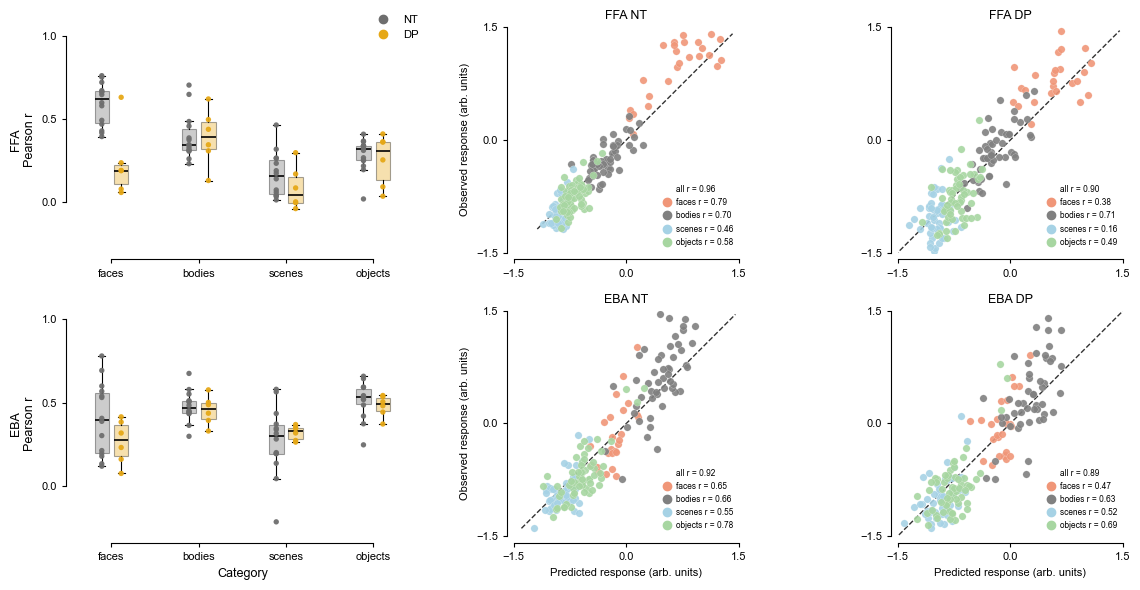

In [282]:
# Group FROIs by hemisphere
froi_groups = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba']
}

# Fallback color map (if not already defined above)
if 'category_colors' not in globals():
    category_colors = {
        'faces': '#f09678',
        'scenes': '#a6d2e5',
        'objects': '#a7d6a1',
        'bodies': '#808080',
    }

fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharex=False, sharey=False)

for row_idx, (froi_group_name, froi_list) in enumerate(froi_groups.items()):
    # -------------------------------------------------------------------------
    # Column 1: Box/scatter of subject-level category correlations (existing)
    # -------------------------------------------------------------------------
    ax_box = axs[row_idx, 0]

    corr_rows = []
    for froi in froi_list:
        for subtype in subtypes:
            df_sub = results_csv[
                (results_csv['froi'] == froi) &
                (results_csv['subject_type'] == subtype)
            ].copy()

            df_stage1 = (
                df_sub
                .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
                .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
            )

            for subject in sorted(df_stage1['test_subject'].unique()):
                for cat in categories:
                    dcat = df_stage1[
                        (df_stage1['test_subject'] == subject) &
                        (df_stage1['img_cat'] == cat)
                    ]

                    if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                        r = np.nan
                    else:
                        r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                    corr_rows.append({
                        'froi': froi,
                        'subject_type': subtype,
                        'test_subject': subject,
                        'img_cat': cat,
                        'r': r
                    })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    # Position setup for boxplots
    step = 0.2
    group_gap = 0.5
    cat_positions = {}
    for cidx, cat in enumerate(categories):
        cat_center = cidx * (step * 2 + group_gap)
        cat_positions[cat] = {
            'nt': cat_center,
            'dp': cat_center + step
        }

    for subtype in subtypes:
        for cidx, cat in enumerate(categories):
            pos = cat_positions[cat][subtype]
            vals = corr_df.loc[
                (corr_df['subject_type'] == subtype) &
                (corr_df['img_cat'] == cat), 'r'
            ].values

            if len(vals) == 0:
                continue

            ax_box.boxplot([vals], positions=[pos], widths=0.15, patch_artist=True,
                           showfliers=False,
                           boxprops=dict(facecolor=subtype_colors[subtype], alpha=0.35, edgecolor='black', linewidth=0.8),
                           medianprops=dict(color='black', linewidth=1.2),
                           whiskerprops=dict(color='black', linewidth=0.8),
                           capprops=dict(color='black', linewidth=0.8))

            x_jitter = rng.normal(loc=pos, scale=0, size=len(vals))
            ax_box.scatter(x_jitter, vals, s=15, alpha=0.95, color=subtype_colors[subtype],
                           edgecolor='none', linewidth=0.4, zorder=3)

    xticks = [np.mean([cat_positions[cat]['nt'], cat_positions[cat]['dp']]) for cat in categories]
    ax_box.set_xticks(xticks)
    ax_box.set_xticklabels(categories, fontsize=8)
    ax_box.set_xlim(-0.3, cat_positions[categories[-1]]['dp'] + 0.3)
    ax_box.set_ylim(-0.3, 1.05)
    ax_box.set_yticks([0.0, 0.5, 1.0])
    ax_box.set_ylabel(f'{froi_group_name.upper()}\nPearson r', fontsize=9)
    if row_idx == 1:
        ax_box.set_xlabel('Category', fontsize=9)

    if row_idx == 0:
        subtype_legend = [
            plt.Line2D([0], [0], color=subtype_colors[st], marker='o', lw=0, label=st.upper())
            for st in subtypes
        ]
        ax_box.legend(handles=subtype_legend, loc='upper right', bbox_to_anchor=(1.05, 1.1),
                      fontsize=8, frameon=False)

    ax_box.spines['top'].set_visible(False)
    ax_box.spines['right'].set_visible(False)
    ax_box.spines['bottom'].set_position(('outward', 5))
    ax_box.spines['left'].set_position(('outward', 5))
    ax_box.spines['left'].set_bounds(0, 1)
    ax_box.spines['bottom'].set_bounds(np.min(xticks), np.max(xticks))
    ax_box.tick_params(axis='both', labelsize=8, length=3, width=0.8)

    # -------------------------------------------------------------------------
    # Columns 2 and 3: Scatter (NT, DP), mean across subjects + hemispheres
    # -------------------------------------------------------------------------
    for col_idx, subtype in enumerate(['nt', 'dp'], start=1):
        ax_scatter = axs[row_idx, col_idx]

        df_sub = results_csv[
            (results_csv['froi'].isin(froi_list)) &
            (results_csv['subject_type'] == subtype)
        ].copy()

        # Stage 1: average repeated entries first
        df_stage1 = (
            df_sub
            .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        # Stage 2: mean across subjects and hemispheres for each stimulus
        df_final = (
            df_stage1
            .groupby(['overall_img_idx', 'img_cat'], as_index=False)
            .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
        )

        # Plot by category color
        for cat in categories:
            dcat = df_final[df_final['img_cat'] == cat]
            if len(dcat) == 0:
                continue
            ax_scatter.scatter(
                dcat['y_prediction'],
                dcat['y_observed'],
                color=category_colors.get(cat, '#808080'),
                alpha=0.9,
                s=28,
                edgecolor='white',
                linewidth=0.15,
                label=cat,
                zorder=3
            )

        # Correlations: all categories + each category
        r_all_label = 'all r = n/a'
        if len(df_final) > 1 and df_final['y_prediction'].nunique() > 1 and df_final['y_observed'].nunique() > 1:
            r_all, _ = pearsonr(df_final['y_prediction'], df_final['y_observed'])
            r_all_label = f'all r = {r_all:.2f}'

        r_cat_labels = []
        for cat in categories:
            dcat = df_final[df_final['img_cat'] == cat]
            if len(dcat) > 1 and dcat['y_prediction'].nunique() > 1 and dcat['y_observed'].nunique() > 1:
                r_cat, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])
                r_cat_labels.append(f'{cat} r = {r_cat:.2f}')
            else:
                r_cat_labels.append(f'{cat} r = n/a')

        if len(df_final) > 1:
            lim_min = min(df_final['y_prediction'].min(), df_final['y_observed'].min())
            lim_max = max(df_final['y_prediction'].max(), df_final['y_observed'].max())
            lims = [lim_min, lim_max]
            ax_scatter.plot(lims, lims, 'k--', linewidth=1, alpha=0.8, zorder=2)

        ax_scatter.set_title(f'{froi_group_name.upper()} {subtype.upper()}', fontsize=9)
        if row_idx == 1:
            ax_scatter.set_xlabel('Predicted response (arb. units)', fontsize=8)
        if col_idx == 1:
            ax_scatter.set_ylabel('Observed response (arb. units)', fontsize=8)

        ax_scatter.spines['top'].set_visible(False)
        ax_scatter.spines['right'].set_visible(False)
        ax_scatter.spines['bottom'].set_position(('outward', 5))
        ax_scatter.spines['left'].set_position(('outward', 5))
        ax_scatter.tick_params(axis='both', labelsize=8, length=3, width=0.8)

        # Legend with category colors + correlation entries (no point symbol)
        # category_legend = [
        #     plt.Line2D([0], [0], color=category_colors[cat], marker='o', lw=0, label=cat)
        #     for cat in categories
        # ]
        corr_legend = [
            plt.Line2D([0], [0], linestyle='None', marker='', color='none', label=r_all_label)
        ] + [
            plt.Line2D([0], [0], linestyle='None', marker='o', color=category_colors[txt.split(' ')[0]], label=txt)
            for txt in r_cat_labels
        ]
        ax_scatter.legend(
            handles= corr_legend, # category_legend
            loc='lower right',
            fontsize=6,
            frameon=False,
            handlelength=1.0,
            handletextpad=0.6,
            borderaxespad=0.3
        )
        ax_scatter.set_aspect('equal')
        ax_scatter.set_xlim(-1.5, 1.5)
        ax_scatter.set_ylim(-1.5, 1.5)
        ax_scatter.set_xticks([-1.5, 0, 1.5])
        ax_scatter.set_yticks([-1.5, 0, 1.5])

plt.tight_layout()
# if savefig:
#     plt.savefig(f'{plot_dir}/martinez_ccn26_fig2_with_scatter.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## v2: Collated

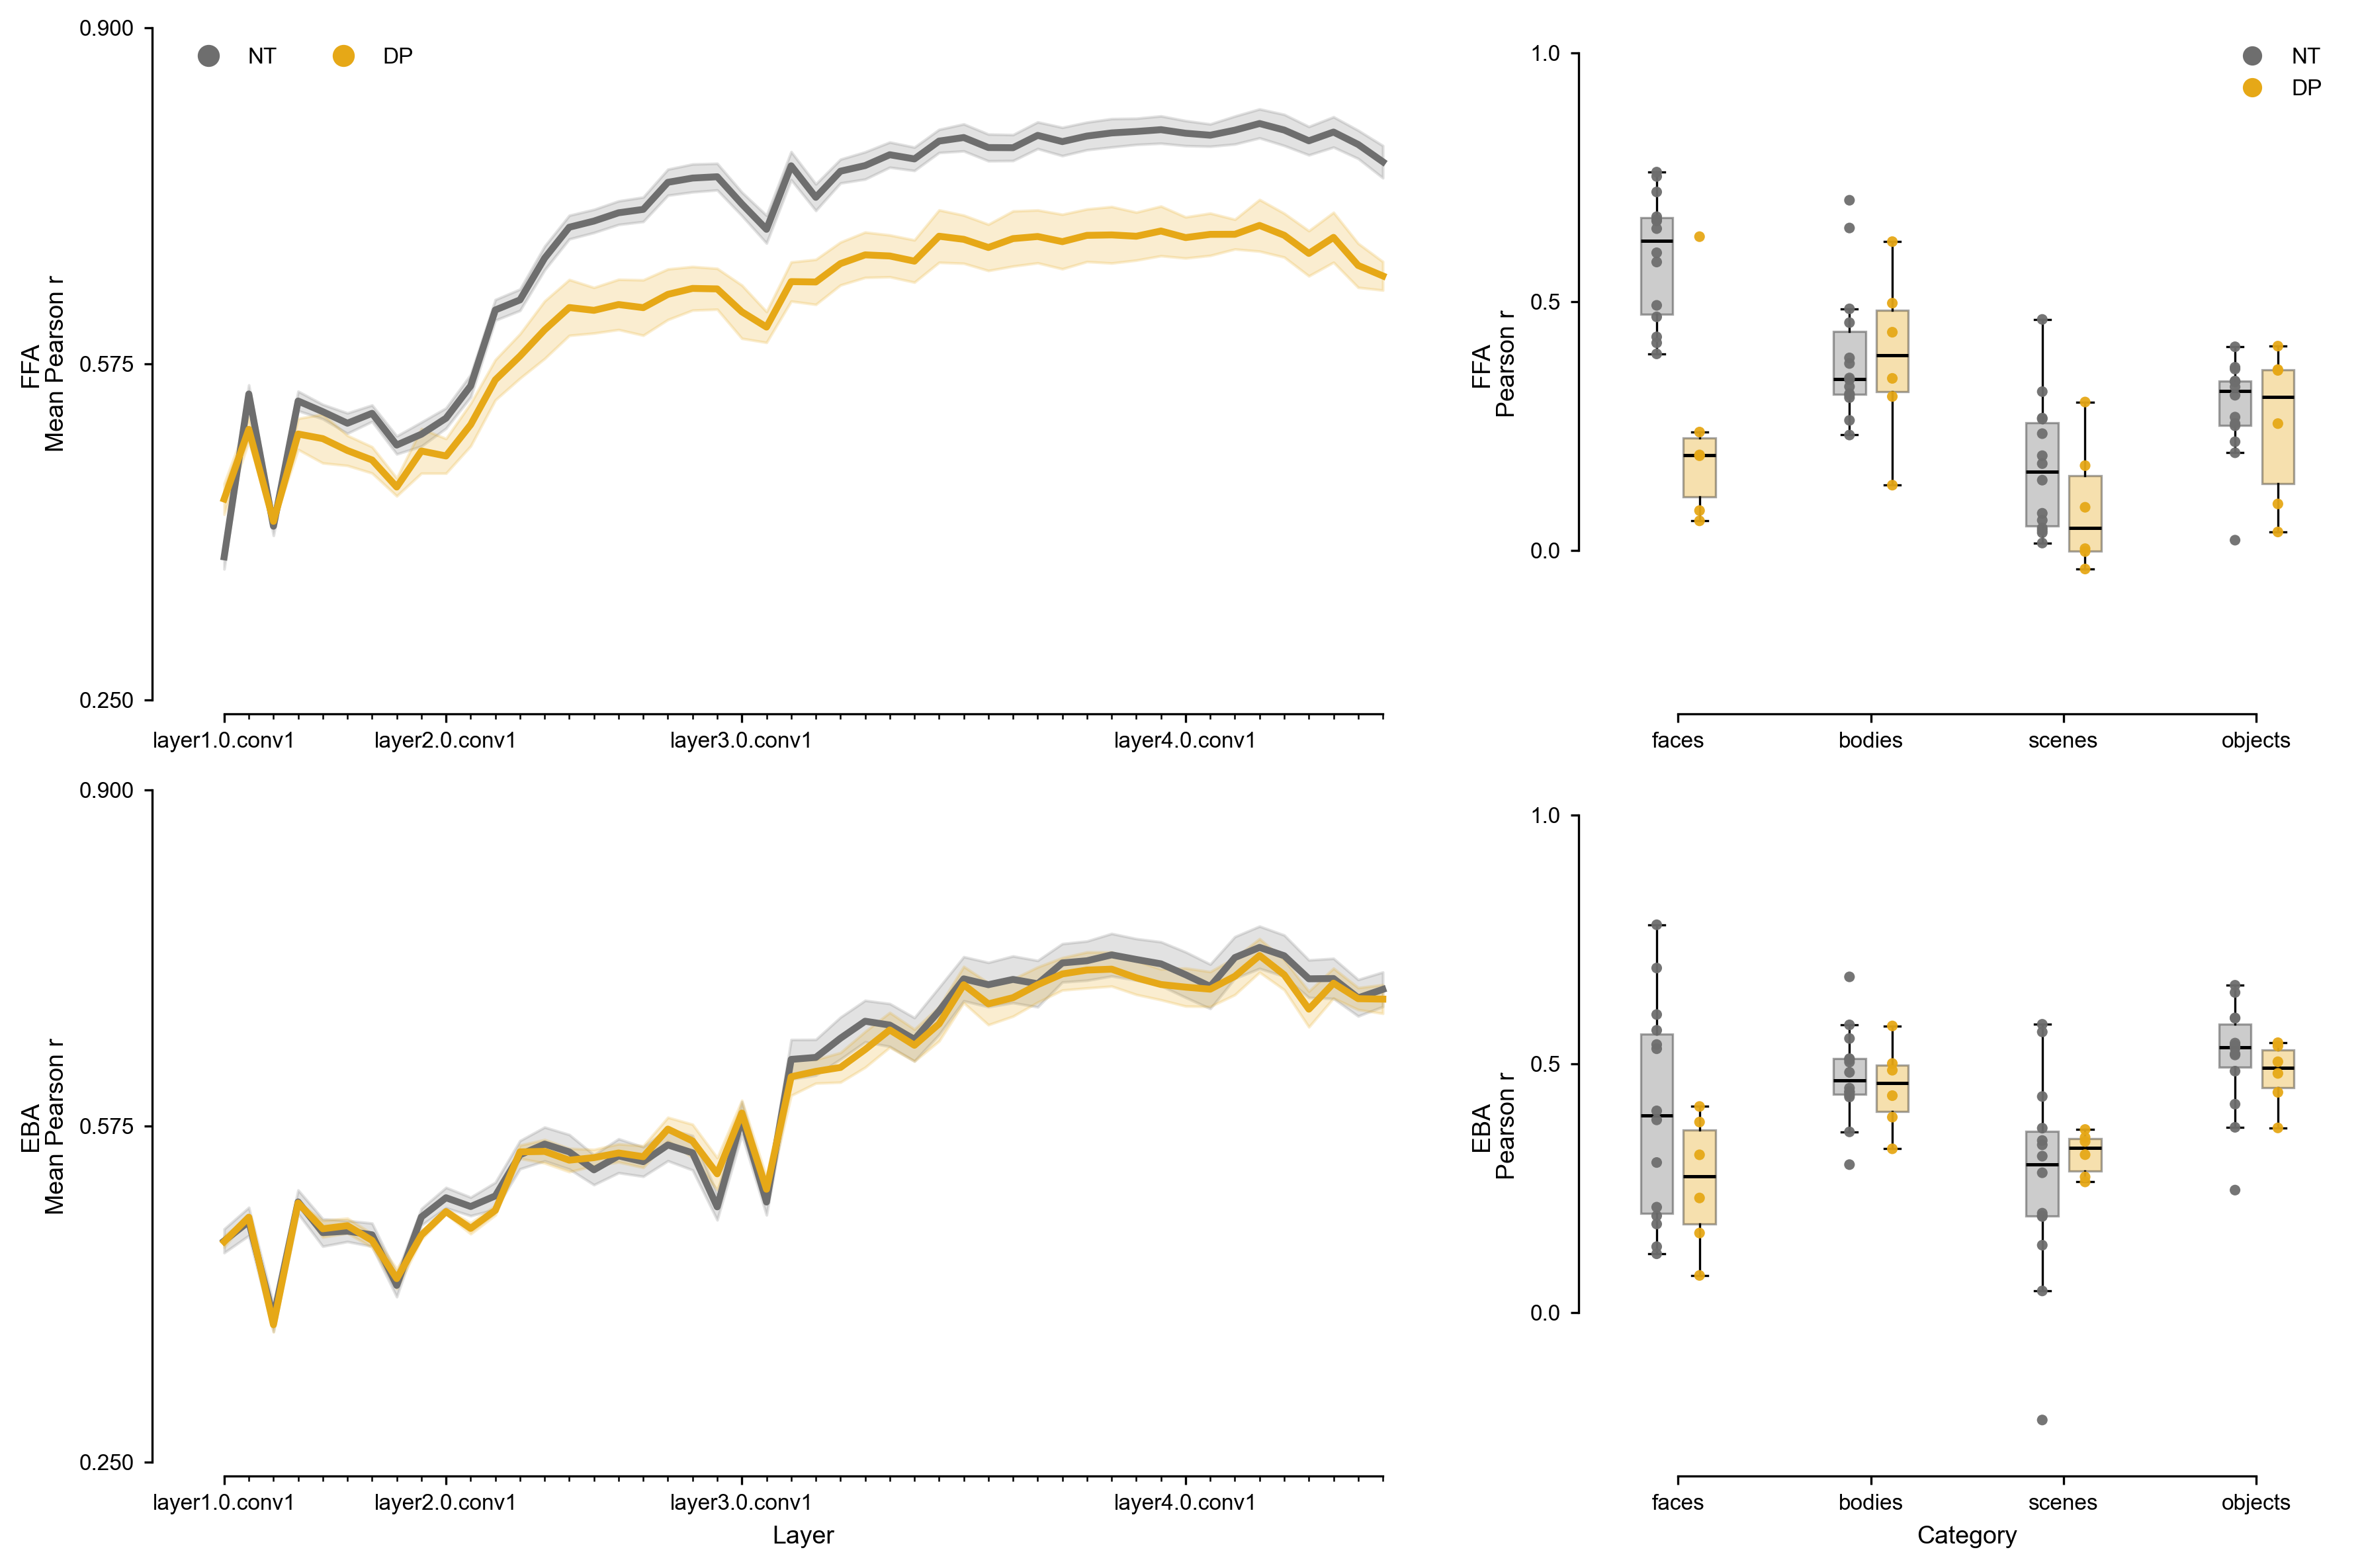

In [281]:
savefig = True
plot_dir = 'results/plots'
os.makedirs(plot_dir, exist_ok=True)

pt1_df = pd.read_csv(f'{RESULTS_DIR}/ccn_pt1.csv')
results_df = pt1_df.copy()

cfrois = ['ffa', 'eba']
subject_types = ['nt', 'dp']
layers = sorted(results_df['layer'].unique())

subtype_colors_dict = {
    'nt': '#6e6e6e',
    'dp': '#E6A817'
}

y_lims_pearsonr_ax1_dict = {
    'ffa': (0.25, 0.9),
    'eba': (0.25, 0.9),
}

# For boxplots (part 2)
subtypes = ['nt', 'dp']
categories = ['faces', 'bodies', 'scenes', 'objects']
subtype_colors = {
    'nt': '#6e6e6e',
    'dp': '#E6A817'
}
rng = np.random.default_rng(0)

# Group FROIs by hemisphere
froi_groups = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba']
}

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt2_stimuli_responses.csv')

# Combined 2x2 figure: rows = FFA/EBA, col1 = line plot, col2 = boxplot
fig, axs = plt.subplots(
    2, 2,
    figsize=(12, 8),
    dpi=300,
    gridspec_kw={'width_ratios': [1.7, 1.0]}
)

for row_idx, cfroi in enumerate(cfrois):
    # ------------------------------
    # Column 1: Hemisphere-averaged line plots
    # ------------------------------
    ax_line = axs[row_idx, 0]

    for subject_type in subject_types:
        st_df = results_df[
            (results_df['froi'].isin([f'l{cfroi}', f'r{cfroi}'])) &
            (results_df['subject_type'] == subject_type)
        ]

        # Average across hemispheres per subject/layer, then across subjects
        hemi_averaged_df = (
            st_df
            .groupby(['test_subject', 'layer'], as_index=False)['mean_pearsonr']
            .mean()
        )
        mean_by_layer = hemi_averaged_df.groupby('layer')['mean_pearsonr'].mean()
        sem_by_layer = hemi_averaged_df.groupby('layer')['mean_pearsonr'].sem()
        layer_indices = [layers.index(layer) for layer in mean_by_layer.index]

        ax_line.plot(
            layer_indices,
            mean_by_layer.values,
            linewidth=2.5,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            linestyle='-',
            label=subject_type.upper()
        )
        ax_line.fill_between(
            layer_indices,
            mean_by_layer.values - sem_by_layer.values,
            mean_by_layer.values + sem_by_layer.values,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            alpha=0.2
        )

    xticks_minor = np.arange(len(layers))
    xticks_major = []
    xticks_major_labels = []
    for lidx, layer in enumerate(layers):
        if '.0.conv1' in layer:
            xticks_major.append(lidx)
            xticks_major_labels.append(layer)

    if len(xticks_major) > 0:
        xticks_minor = np.delete(xticks_minor, xticks_major)

    ax_line.set_ylabel(f'{cfroi.upper()}\nMean Pearson r', fontsize=9)
    if row_idx == len(cfrois) - 1:
        ax_line.set_xlabel('Layer', fontsize=9)

    legend_elements = [
        Line2D([0], [0], color=subtype_colors_dict['nt'], marker='o', markersize=7, lw=0, label='NT'),
        Line2D([0], [0], color=subtype_colors_dict['dp'], marker='o', markersize=7, lw=0, label='DP'),
    ]
    if row_idx == 0:
        ax_line.legend(handles=legend_elements, frameon=False, loc='upper left', ncol=2, fontsize=8)

    ax_line.spines['top'].set_visible(False)
    ax_line.spines['right'].set_visible(False)
    ax_line.spines['bottom'].set_position(('outward', 5))
    ax_line.spines['left'].set_position(('outward', 5))

    if len(xticks_major) > 0 and len(xticks_minor) > 0:
        ax_line.spines['bottom'].set_bounds((np.min(xticks_major), np.max(xticks_minor)))

    ax_line.set_xticks(xticks_major, minor=False)
    ax_line.set_xticklabels(xticks_major_labels, fontsize=7)
    ax_line.set_xticks(xticks_minor, minor=True)

    ylims = y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))
    ax_line.set_ylim(ylims)
    yticks = np.linspace(np.min(ylims), np.max(ylims), num=3)
    ax_line.set_yticks(yticks)
    ax_line.spines['left'].set_bounds(np.min(ylims), np.max(ylims))
    ax_line.tick_params(axis='both', labelsize=8, length=3, width=0.8)

    # ------------------------------
    # Column 2: Boxplots (hemispheres collated)
    # ------------------------------
    ax_box = axs[row_idx, 1]
    froi_list = froi_groups[cfroi]

    corr_rows = []
    for froi in froi_list:
        for subtype in subtypes:
            df_sub = results_csv[
                (results_csv['froi'] == froi) &
                (results_csv['subject_type'] == subtype)
            ].copy()

            df_stage1 = (
                df_sub
                .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
                .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
            )

            for subject in sorted(df_stage1['test_subject'].unique()):
                for cat in categories:
                    dcat = df_stage1[
                        (df_stage1['test_subject'] == subject) &
                        (df_stage1['img_cat'] == cat)
                    ]

                    if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                        r = np.nan
                    else:
                        r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                    corr_rows.append({
                        'subject_type': subtype,
                        'img_cat': cat,
                        'r': r
                    })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    step = 0.2
    group_gap = 0.5
    cat_positions = {}
    for cidx, cat in enumerate(categories):
        cat_center = cidx * (step * 2 + group_gap)
        cat_positions[cat] = {
            'nt': cat_center,
            'dp': cat_center + step
        }

    for subtype in subtypes:
        for cat in categories:
            pos = cat_positions[cat][subtype]
            vals = corr_df.loc[
                (corr_df['subject_type'] == subtype) &
                (corr_df['img_cat'] == cat), 'r'
            ].values

            if len(vals) == 0:
                continue

            ax_box.boxplot(
                [vals],
                positions=[pos],
                widths=0.15,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor=subtype_colors[subtype], alpha=0.35, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1.2),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8)
            )

            x_jitter = rng.normal(loc=pos, scale=0, size=len(vals))
            ax_box.scatter(
                x_jitter,
                vals,
                s=15,
                alpha=0.95,
                color=subtype_colors[subtype],
                edgecolor='none',
                linewidth=0.4,
                zorder=3
            )

    xticks = [np.mean([cat_positions[cat]['nt'], cat_positions[cat]['dp']]) for cat in categories]
    ax_box.set_xticks(xticks)
    ax_box.set_xticklabels(categories, fontsize=8)
    ax_box.set_xlim(-0.3, cat_positions[categories[-1]]['dp'] + 0.3)
    ax_box.set_ylim(-0.3, 1.05)
    ax_box.set_yticks([0.0, 0.5, 1.0])
    ax_box.set_ylabel(f'{cfroi.upper()}\nPearson r', fontsize=9)

    if row_idx == len(cfrois) - 1:
        ax_box.set_xlabel('Category', fontsize=9)

    if row_idx == 0:
        subtype_legend = [
            plt.Line2D([0], [0], color=subtype_colors[st], marker='o', lw=0, label=st.upper())
            for st in subtypes
        ]
        ax_box.legend(handles=subtype_legend, loc='upper right', fontsize=8, frameon=False)

    ax_box.spines['top'].set_visible(False)
    ax_box.spines['right'].set_visible(False)
    ax_box.spines['bottom'].set_position(('outward', 5))
    ax_box.spines['left'].set_position(('outward', 5))
    ax_box.spines['left'].set_bounds(0, 1)
    ax_box.spines['bottom'].set_bounds(np.min(xticks), np.max(xticks))
    ax_box.tick_params(axis='both', labelsize=8, length=3, width=0.8)

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig1.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# Fig3

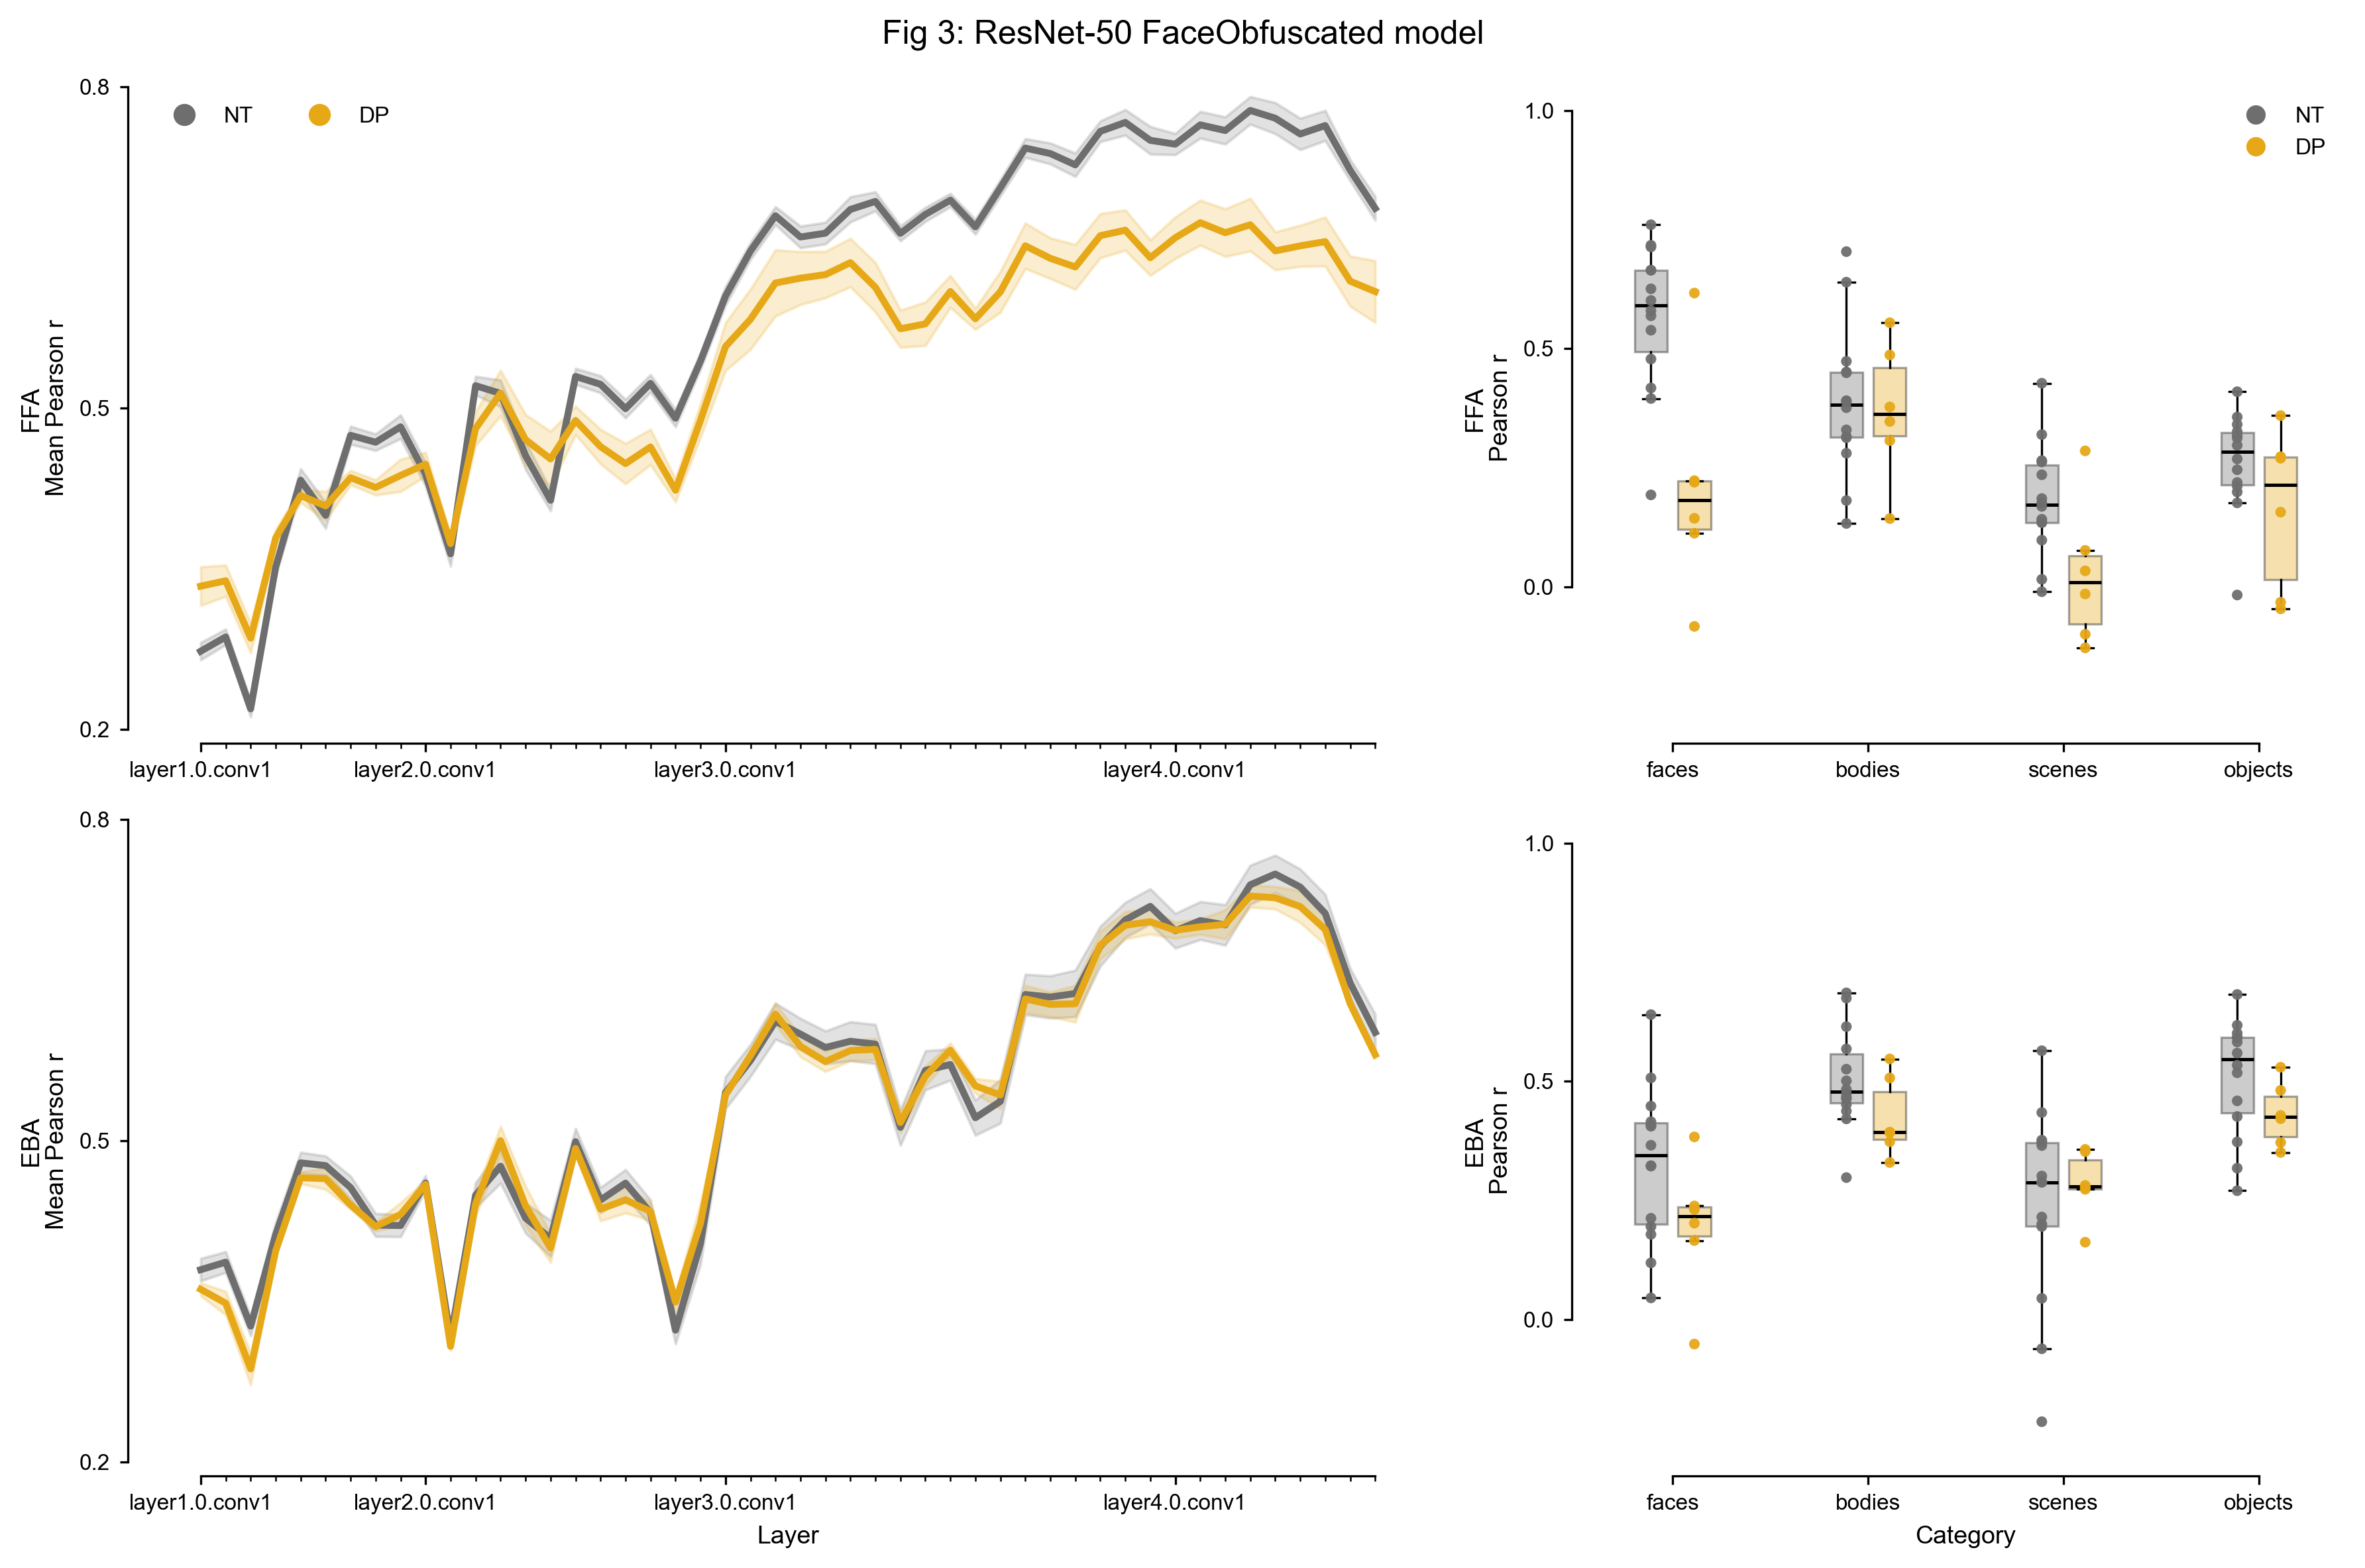

In [288]:
savefig = False
plot_dir = 'results/plots'
os.makedirs(plot_dir, exist_ok=True)

pt1_df = pd.read_csv(f'{RESULTS_DIR}/ccn_pt3_faceobfuscation.csv')
results_df = pt1_df.copy()

cfrois = ['ffa', 'eba']
subject_types = ['nt', 'dp']
layers = sorted(results_df['layer'].unique())

subtype_colors_dict = {
    'nt': '#6e6e6e',
    'dp': '#E6A817'
}

y_lims_pearsonr_ax1_dict = {
    'ffa': (0.2, 0.8),
    'eba': (0.2, 0.8),
}

# For boxplots (part 2)
subtypes = ['nt', 'dp']
categories = ['faces', 'bodies', 'scenes', 'objects']
subtype_colors = {
    'nt': '#6e6e6e',
    'dp': '#E6A817'
}
rng = np.random.default_rng(0)

# Group FROIs by hemisphere
froi_groups = {
    'ffa': ['lffa', 'rffa'],
    'eba': ['leba', 'reba']
}

results_csv = pd.read_csv(f'{RESULTS_DIR}/ccn_pt3_faceobfuscation_stimuli_responses.csv')

# Combined 2x2 figure: rows = FFA/EBA, col1 = line plot, col2 = boxplot
fig, axs = plt.subplots(
    2, 2,
    figsize=(12, 8),
    dpi=300,
    gridspec_kw={'width_ratios': [1.7, 1.0]}
)

for row_idx, cfroi in enumerate(cfrois):
    # ------------------------------
    # Column 1: Hemisphere-averaged line plots
    # ------------------------------
    ax_line = axs[row_idx, 0]

    for subject_type in subject_types:
        st_df = results_df[
            (results_df['froi'].isin([f'l{cfroi}', f'r{cfroi}'])) &
            (results_df['subject_type'] == subject_type)
        ]

        # Average across hemispheres per subject/layer, then across subjects
        hemi_averaged_df = (
            st_df
            .groupby(['test_subject', 'layer'], as_index=False)['mean_pearsonr']
            .mean()
        )
        mean_by_layer = hemi_averaged_df.groupby('layer')['mean_pearsonr'].mean()
        sem_by_layer = hemi_averaged_df.groupby('layer')['mean_pearsonr'].sem()
        layer_indices = [layers.index(layer) for layer in mean_by_layer.index]

        ax_line.plot(
            layer_indices,
            mean_by_layer.values,
            linewidth=2.5,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            linestyle='-',
            label=subject_type.upper()
        )
        ax_line.fill_between(
            layer_indices,
            mean_by_layer.values - sem_by_layer.values,
            mean_by_layer.values + sem_by_layer.values,
            color=subtype_colors_dict.get(subject_type, '#000000'),
            alpha=0.2
        )

    xticks_minor = np.arange(len(layers))
    xticks_major = []
    xticks_major_labels = []
    for lidx, layer in enumerate(layers):
        if '.0.conv1' in layer:
            xticks_major.append(lidx)
            xticks_major_labels.append(layer)

    if len(xticks_major) > 0:
        xticks_minor = np.delete(xticks_minor, xticks_major)

    ax_line.set_ylabel(f'{cfroi.upper()}\nMean Pearson r', fontsize=9)
    if row_idx == len(cfrois) - 1:
        ax_line.set_xlabel('Layer', fontsize=9)

    legend_elements = [
        Line2D([0], [0], color=subtype_colors_dict['nt'], marker='o', markersize=7, lw=0, label='NT'),
        Line2D([0], [0], color=subtype_colors_dict['dp'], marker='o', markersize=7, lw=0, label='DP'),
    ]
    if row_idx == 0:
        ax_line.legend(handles=legend_elements, frameon=False, loc='upper left', ncol=2, fontsize=8)

    ax_line.spines['top'].set_visible(False)
    ax_line.spines['right'].set_visible(False)
    ax_line.spines['bottom'].set_position(('outward', 5))
    ax_line.spines['left'].set_position(('outward', 5))

    if len(xticks_major) > 0 and len(xticks_minor) > 0:
        ax_line.spines['bottom'].set_bounds((np.min(xticks_major), np.max(xticks_minor)))

    ax_line.set_xticks(xticks_major, minor=False)
    ax_line.set_xticklabels(xticks_major_labels, fontsize=7)
    ax_line.set_xticks(xticks_minor, minor=True)

    ylims = y_lims_pearsonr_ax1_dict.get(cfroi, (0, 1))
    ax_line.set_ylim(ylims)
    yticks = np.linspace(np.min(ylims), np.max(ylims), num=3)
    ax_line.set_yticks(yticks)
    ax_line.spines['left'].set_bounds(np.min(ylims), np.max(ylims))
    ax_line.tick_params(axis='both', labelsize=8, length=3, width=0.8)

    # ------------------------------
    # Column 2: Boxplots (hemispheres collated)
    # ------------------------------
    ax_box = axs[row_idx, 1]
    froi_list = froi_groups[cfroi]

    corr_rows = []
    for froi in froi_list:
        for subtype in subtypes:
            df_sub = results_csv[
                (results_csv['froi'] == froi) &
                (results_csv['subject_type'] == subtype)
            ].copy()

            df_stage1 = (
                df_sub
                .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
                .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
            )

            for subject in sorted(df_stage1['test_subject'].unique()):
                for cat in categories:
                    dcat = df_stage1[
                        (df_stage1['test_subject'] == subject) &
                        (df_stage1['img_cat'] == cat)
                    ]

                    if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                        r = np.nan
                    else:
                        r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                    corr_rows.append({
                        'subject_type': subtype,
                        'img_cat': cat,
                        'r': r
                    })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    step = 0.2
    group_gap = 0.5
    cat_positions = {}
    for cidx, cat in enumerate(categories):
        cat_center = cidx * (step * 2 + group_gap)
        cat_positions[cat] = {
            'nt': cat_center,
            'dp': cat_center + step
        }

    for subtype in subtypes:
        for cat in categories:
            pos = cat_positions[cat][subtype]
            vals = corr_df.loc[
                (corr_df['subject_type'] == subtype) &
                (corr_df['img_cat'] == cat), 'r'
            ].values

            if len(vals) == 0:
                continue

            ax_box.boxplot(
                [vals],
                positions=[pos],
                widths=0.15,
                patch_artist=True,
                showfliers=False,
                boxprops=dict(facecolor=subtype_colors[subtype], alpha=0.35, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1.2),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8)
            )

            x_jitter = rng.normal(loc=pos, scale=0, size=len(vals))
            ax_box.scatter(
                x_jitter,
                vals,
                s=15,
                alpha=0.95,
                color=subtype_colors[subtype],
                edgecolor='none',
                linewidth=0.4,
                zorder=3
            )

    xticks = [np.mean([cat_positions[cat]['nt'], cat_positions[cat]['dp']]) for cat in categories]
    ax_box.set_xticks(xticks)
    ax_box.set_xticklabels(categories, fontsize=8)
    ax_box.set_xlim(-0.3, cat_positions[categories[-1]]['dp'] + 0.3)
    ax_box.set_ylim(-0.3, 1.05)
    ax_box.set_yticks([0.0, 0.5, 1.0])
    ax_box.set_ylabel(f'{cfroi.upper()}\nPearson r', fontsize=9)

    if row_idx == len(cfrois) - 1:
        ax_box.set_xlabel('Category', fontsize=9)

    if row_idx == 0:
        subtype_legend = [
            plt.Line2D([0], [0], color=subtype_colors[st], marker='o', lw=0, label=st.upper())
            for st in subtypes
        ]
        ax_box.legend(handles=subtype_legend, loc='upper right', fontsize=8, frameon=False)

    ax_box.spines['top'].set_visible(False)
    ax_box.spines['right'].set_visible(False)
    ax_box.spines['bottom'].set_position(('outward', 5))
    ax_box.spines['left'].set_position(('outward', 5))
    ax_box.spines['left'].set_bounds(0, 1)
    ax_box.spines['bottom'].set_bounds(np.min(xticks), np.max(xticks))
    ax_box.tick_params(axis='both', labelsize=8, length=3, width=0.8)

plt.suptitle(f'Fig 3: ResNet-50 FaceObfuscated model')
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/martinez_ccn26_fig3.pdf', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [285]:
from scipy.stats import mannwhitneyu

# Mann-Whitney U: NT vs DP after collating points across hemispheres
# Example: FFA = lffa + rffa, EBA = leba + reba
if 'froi_groups' not in globals():
    froi_groups = {
        'ffa': ['lffa', 'rffa'],
        'eba': ['leba', 'reba'],
    }

mw_hemi_rows = []

for froi_group_name, froi_list in froi_groups.items():
    corr_rows = []

    for froi in froi_list:
        for subtype in subtypes:
            df_sub = results_csv[
                (results_csv['froi'] == froi) &
                (results_csv['subject_type'] == subtype)
            ].copy()

            df_stage1 = (
                df_sub
                .groupby(['test_subject', 'overall_img_idx', 'img_cat'], as_index=False)
                .agg({'y_prediction': 'mean', 'y_observed': 'mean'})
            )

            for subject in sorted(df_stage1['test_subject'].unique()):
                for cat in categories:
                    dcat = df_stage1[
                        (df_stage1['test_subject'] == subject) &
                        (df_stage1['img_cat'] == cat)
                    ]

                    if len(dcat) < 2 or dcat['y_prediction'].nunique() < 2 or dcat['y_observed'].nunique() < 2:
                        r = np.nan
                    else:
                        r, _ = pearsonr(dcat['y_prediction'], dcat['y_observed'])

                    corr_rows.append({
                        'froi_group': froi_group_name,
                        'froi': froi,
                        'subject_type': subtype,
                        'test_subject': subject,
                        'img_cat': cat,
                        'r': r
                    })

    corr_df = pd.DataFrame(corr_rows).dropna(subset=['r'])

    for cat in categories:
        nt_vals = corr_df.loc[
            (corr_df['subject_type'] == 'nt') & (corr_df['img_cat'] == cat), 'r'
        ].values
        dp_vals = corr_df.loc[
            (corr_df['subject_type'] == 'dp') & (corr_df['img_cat'] == cat), 'r'
        ].values

        if len(nt_vals) > 0 and len(dp_vals) > 0:
            u_stat, p_value = mannwhitneyu(nt_vals, dp_vals, alternative='two-sided')
        else:
            u_stat, p_value = np.nan, np.nan

        mw_hemi_rows.append({
            'froi_group': froi_group_name,
            'category': cat,
            'n_nt': len(nt_vals),
            'n_dp': len(dp_vals),
            'median_nt_r': np.median(nt_vals) if len(nt_vals) else np.nan,
            'median_dp_r': np.median(dp_vals) if len(dp_vals) else np.nan,
            'u_stat': u_stat,
            'p_value': p_value
        })

mw_hemi_df = pd.DataFrame(mw_hemi_rows)
mw_hemi_df['p_fdr_bh'] = np.nan

# Benjamini-Hochberg FDR correction across all hemisphere-collated tests
valid_mask = mw_hemi_df['p_value'].notna()
pvals = mw_hemi_df.loc[valid_mask, 'p_value'].values
m = len(pvals)
if m > 0:
    order = np.argsort(pvals)
    ranked = pvals[order]
    qvals = np.empty_like(ranked, dtype=float)
    prev = 1.0
    for i in range(m - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * m / rank
        prev = min(prev, val)
        qvals[i] = prev
    qvals_original_order = np.empty_like(qvals)
    qvals_original_order[order] = qvals
    mw_hemi_df.loc[valid_mask, 'p_fdr_bh'] = np.clip(qvals_original_order, 0, 1)

mw_hemi_df['sig_0.05'] = mw_hemi_df['p_value'] < 0.05
mw_hemi_df['sig_fdr_0.05'] = mw_hemi_df['p_fdr_bh'] < 0.05

# mw_hemi_df = mw_hemi_df.sort_values(['froi_group', 'category']).reset_index(drop=True)

display(mw_hemi_df)
print(f'Total tests: {mw_hemi_df["p_value"].notna().sum()}')
print(f'Significant (uncorrected p < 0.05): {mw_hemi_df["sig_0.05"].sum()}')
print(f'Significant (FDR q < 0.05): {mw_hemi_df["sig_fdr_0.05"].sum()}')

,froi_group,category,n_nt,n_dp,median_nt_r,median_dp_r,u_stat,p_value,p_fdr_bh,sig_0.05,sig_fdr_0.05
0,ffa,faces,14,6,0.590391,0.181486,74.0,0.006450,0.051600,True,False
1,ffa,bodies,14,6,0.382632,0.362229,43.0,0.967957,0.967957,False,False
2,ffa,scenes,14,6,0.172428,0.008914,68.0,0.032559,0.130237,True,False
3,ffa,objects,14,6,0.282612,0.213141,56.0,0.274045,0.365394,False,False
4,eba,faces,14,6,0.344364,0.216519,60.0,0.152838,0.244541,False,False
5,eba,bodies,14,6,0.478777,0.392865,61.0,0.129670,0.244541,False,False
6,eba,scenes,14,6,0.288251,0.279567,45.0,0.841125,0.961286,False,False
7,eba,objects,14,6,0.546671,0.425020,62.0,0.109340,0.244541,False,False


Total tests: 8
Significant (uncorrected p < 0.05): 2
Significant (FDR q < 0.05): 0
